## Python Visualizations using Matplotlib and Seaborn

### Loading the data

In [ ]:
import pandas as pd

df = pd.read_csv("penglings.csv")

## Matplotlib

Text(0, 0.5, 'Body Mass (g)')

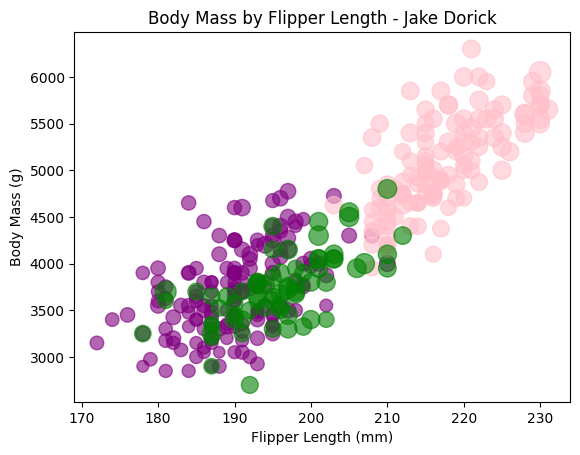

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(
    df.flipper_length_mm,
    df.body_mass_g,
    s=df.bill_length_mm**2 / 15,
    c=df.species.map({"Adelie": "purple", "Chinstrap": "green", "Gentoo": "pink"}),
    alpha=0.6,
)
plt.title("Body Mass by Flipper Length - Jake Dorick")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

### Seaborn

Text(0, 0.5, 'Body Mass (g)')

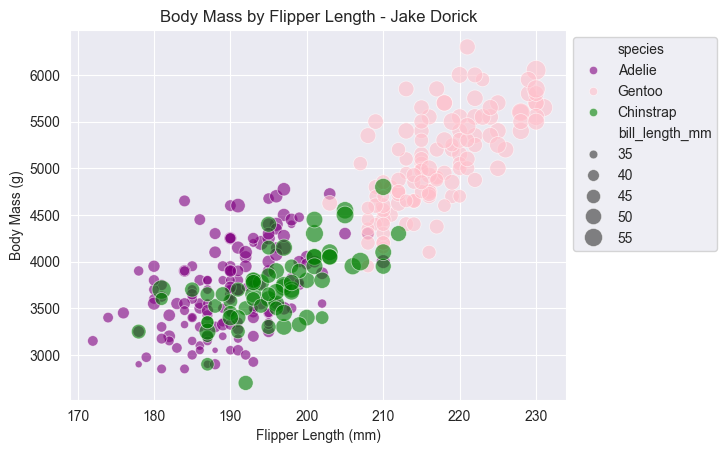

In [ ]:
import seaborn as sns

sns.set_style("darkgrid")
sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette={"Adelie": "purple", "Chinstrap": "green", "Gentoo": "pink"},
    size="bill_length_mm",
    sizes=(20, 200),
    alpha=0.6,
)
sns.move_legend(plt.gca(), "upper left", bbox_to_anchor=(1, 1))

plt.title("Body Mass by Flipper Length - Jake Dorick")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

## Altair

In [38]:
import altair as alt

pick = alt.selection_point(on="click", empty=False)
interactive_chart = (
    alt.Chart(df)
    .mark_circle(size=80)
    .encode(
        x=alt.X(
            "flipper_length_mm",
            title="Flipper Length (mm)",
            scale=alt.Scale(zero=False),
        ),
        y=alt.Y("body_mass_g", title="Body Mass (g)", scale=alt.Scale(zero=False)),
        color=alt.Color(
            "species",
            title="Species",
            scale=alt.Scale(
                domain=["Adelie", "Chinstrap", "Gentoo"],
                range=["#BF94B3", "#006400", "#FFC0CB"],
            ),
        ),
        size=alt.Size("bill_length_mm", title="Bill Length (mm)"),
        tooltip=["bill_length_mm", "species", "flipper_length_mm", "body_mass_g"],
        opacity=alt.condition(pick, alt.value(1), alt.value(0.8)),
        stroke=alt.condition(pick, alt.value("black"), alt.value(None)),
        strokeWidth=alt.condition(pick, alt.value(2.5), alt.value(0)),
    )
    .add_params(pick)
    .properties(
        title="Body Mass by Flipper Length - Jake Dorick", width=500, height=350
    )
    .configure(font="Calibri")
    .configure_view(
        fill="#EBEBEB",
        stroke=None,
    )
    .configure_title(
        fontSize=16,
    )
    .interactive()
)

interactive_chart

alt.Chart(...)